# Exploratory Storyboarding

Exploration produces dozens of charts; a reader needs five or six in a clear order. **Storyboarding** turns an analysis into a sequence of charts, each answering one question that leads to the next, from context to conclusion.

**After this lesson you can:**

1. Write the analytical question and the sub-questions that answer it.
2. Plan a storyboard: context, pattern, breakdown, anomaly, explanation, implication.
3. Build each panel with a message title and consistent visual language.
4. Assemble the storyboard and review it against a checklist.

**Data:** NYC yellow taxi trips, January and February 2024.

**The question:** *How important are airport trips for the yellow taxi business, and what drives their value?*

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent / "tools"))
import datasets                                   # course helper: downloads pinned public datasets

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 100})

COLS = ["tpep_pickup_datetime", "tpep_dropoff_datetime", "PULocationID", "DOLocationID", "trip_distance",
        "fare_amount", "tip_amount", "total_amount", "payment_type"]

def load_month(month: str) -> pd.DataFrame:
    """One month of NYC yellow taxi trips with the cleaning rules of M08 Lesson 08."""
    df = pd.read_parquet(datasets.taxi(month), columns=COLS)
    start = pd.Timestamp(month + "-01")
    dur = (df["tpep_dropoff_datetime"] - df["tpep_pickup_datetime"]).dt.total_seconds() / 60
    ok = (df["tpep_pickup_datetime"].between(start, start + pd.offsets.MonthBegin(1), inclusive="left")
          & dur.between(1, 180) & df["trip_distance"].between(0.1, 100) & df["fare_amount"].between(3, 500))
    return df[ok].assign(duration_min=dur[ok])

zones = pd.read_csv(datasets.fetch("taxi_zone_lookup.csv"))

trips = pd.concat([load_month("2024-01"), load_month("2024-02")], ignore_index=True)
airports = {132: "JFK", 138: "LaGuardia"}
trips["segment"] = np.where(trips["PULocationID"].isin(airports.keys()) | trips["DOLocationID"].isin(airports.keys()),
                            "airport", "city")
trips["airport"] = trips["PULocationID"].map(airports).fillna(trips["DOLocationID"].map(airports))
ACCENT, CONTEXT = "#E15759", "#BAB0AC"
print(f"{len(trips):,} trips | airport share: {(trips['segment'] == 'airport').mean():.1%}")

5,741,619 trips | airport share: 9.2%


## 1. Plan the Storyboard

| # | Role | Sub-question | Chart |
| :-: | :--- | :--- | :--- |
| 1 | context | how big is the business? | KPI numbers |
| 2 | pattern | what share of trips and revenue do airports bring? | two bars |
| 3 | breakdown | why is an airport trip worth more? | distance and fare distributions |
| 4 | timing | when do airport trips happen? | hour-of-day lines |
| 5 | anomaly | are there days when airport demand breaks the pattern? | daily line with markers |
| 6 | implication | what does an hour of driving earn in each segment? | revenue per hour bars |

One accent colour (airport) and one context colour (city) are used in **every** panel, so the reader learns the code once.

## 2. Build the Panels

In [2]:
seg = trips.groupby("segment").agg(trips=("fare_amount", "size"), revenue=("total_amount", "sum"),
                                   hours=("duration_min", lambda s: s.sum() / 60))
share = seg[["trips", "revenue"]] / seg[["trips", "revenue"]].sum()
daily = trips[trips["segment"] == "airport"].groupby(trips["tpep_pickup_datetime"].dt.date).size()
daily.index = pd.to_datetime(daily.index)
weekday_median = daily.groupby(daily.index.day_of_week).transform("median")
odd = daily[(daily / weekday_median - 1).abs() > 0.15]
by_hour = trips.groupby([trips["tpep_pickup_datetime"].dt.hour, "segment"]).size().unstack()
by_hour = by_hour / by_hour.sum()
per_hour = seg["revenue"] / seg["hours"]
print(share.round(3), "\n")
print("revenue per driving hour:", per_hour.round(1).to_dict())
print("unusual airport days:", [d.strftime("%a %d %b") for d in odd.index])

         trips  revenue
segment                
airport  0.092    0.257
city     0.908    0.743 

revenue per driving hour: {'airport': 130.9, 'city': 101.4}
unusual airport days: ['Tue 02 Jan', 'Wed 03 Jan', 'Sat 06 Jan', 'Sat 13 Jan', 'Tue 16 Jan', 'Fri 19 Jan', 'Tue 13 Feb', 'Mon 19 Feb', 'Tue 20 Feb', 'Tue 27 Feb']


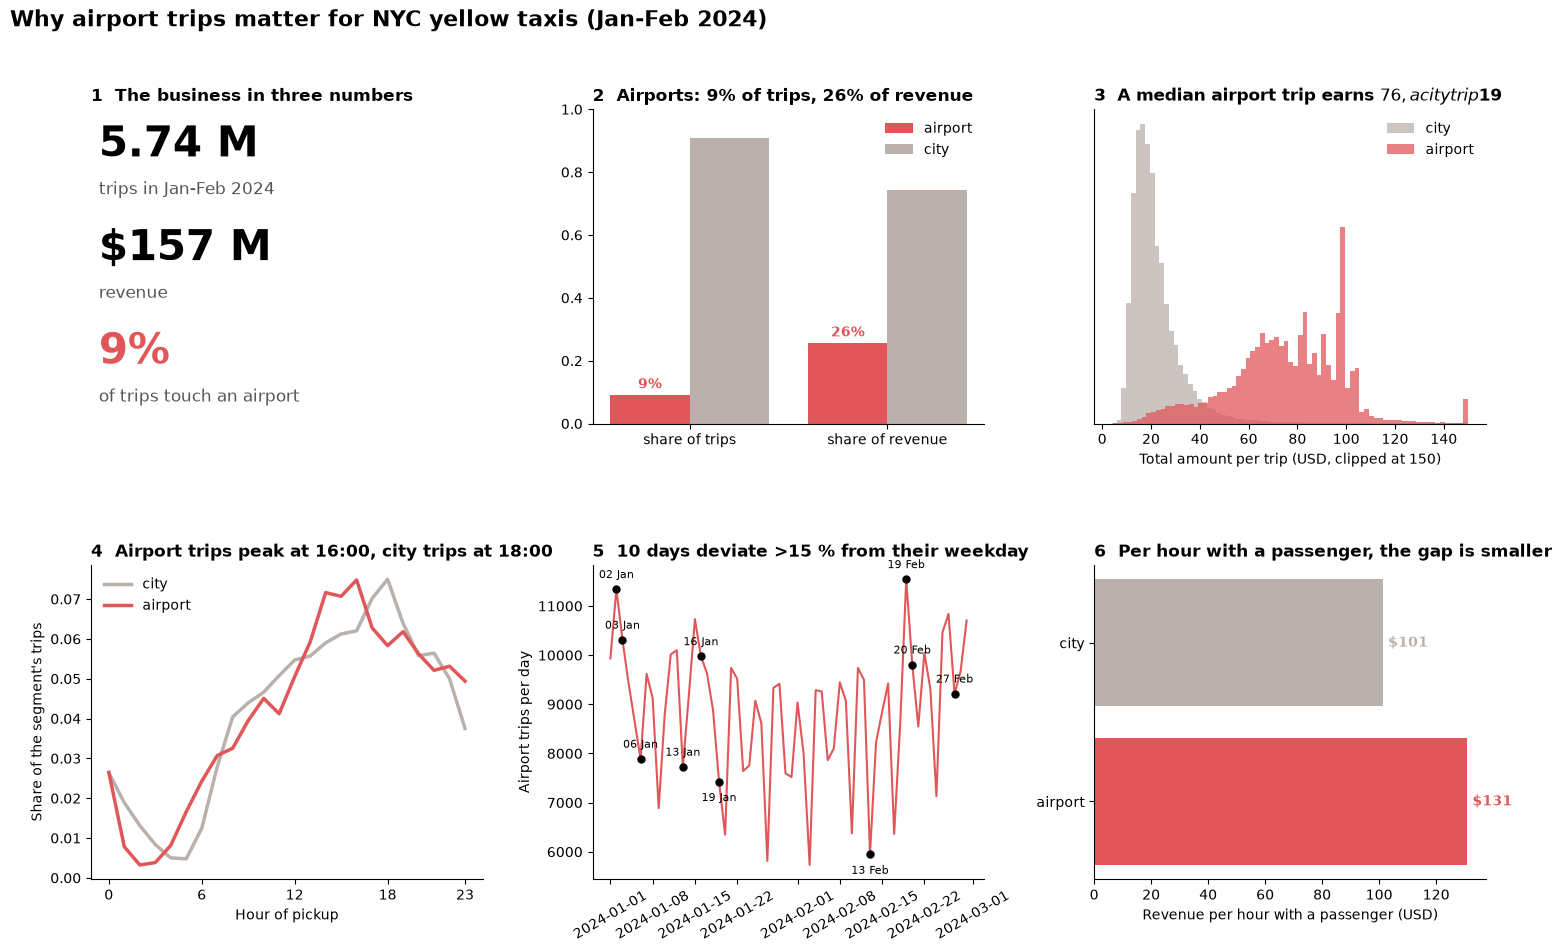

In [3]:
fig = plt.figure(figsize=(18, 10))
gs = fig.add_gridspec(2, 3, hspace=0.45, wspace=0.28)
colors = {"airport": ACCENT, "city": CONTEXT}

ax = fig.add_subplot(gs[0, 0]); ax.axis("off")
kpis = [(f"{len(trips) / 1e6:.2f} M", "trips in Jan-Feb 2024"), (f"${trips['total_amount'].sum() / 1e6:.0f} M", "revenue"),
        (f"{share.loc['airport', 'trips']:.0%}", "of trips touch an airport")]
for i, (big, small) in enumerate(kpis):
    ax.text(0.02, 0.85 - i * 0.33, big, fontsize=30, fontweight="bold", color=ACCENT if i == 2 else "black")
    ax.text(0.02, 0.73 - i * 0.33, small, fontsize=12, color="#555555")
ax.set_title("1  The business in three numbers", loc="left", fontweight="bold")

ax = fig.add_subplot(gs[0, 1])
x = np.arange(2)
ax.bar(x - 0.2, share.loc["airport"], 0.4, color=ACCENT, label="airport")
ax.bar(x + 0.2, share.loc["city"], 0.4, color=CONTEXT, label="city")
ax.set(xticks=x, xticklabels=["share of trips", "share of revenue"], ylim=(0, 1))
for i, col in enumerate(["trips", "revenue"]):
    ax.text(i - 0.2, share.loc["airport", col] + 0.02, f"{share.loc['airport', col]:.0%}", ha="center", color=ACCENT, fontweight="bold")
ax.set_title(f"2  Airports: {share.loc['airport', 'trips']:.0%} of trips, {share.loc['airport', 'revenue']:.0%} of revenue", loc="left", fontweight="bold")
ax.legend(frameon=False)

ax = fig.add_subplot(gs[0, 2])
for s in ["city", "airport"]:
    ax.hist(trips.loc[trips["segment"] == s, "total_amount"].clip(upper=150), bins=75, density=True, alpha=0.75, color=colors[s], label=s)
med = trips.groupby("segment")["total_amount"].median()
ax.set(xlabel="Total amount per trip (USD, clipped at 150)", yticks=[])
ax.set_title(f"3  A median airport trip earns ${med['airport']:.0f}, a city trip ${med['city']:.0f}", loc="left", fontweight="bold")
ax.legend(frameon=False)

ax = fig.add_subplot(gs[1, 0])
for s in ["city", "airport"]:
    ax.plot(by_hour.index, by_hour[s], color=colors[s], lw=2.5, label=s)
ax.set(xlabel="Hour of pickup", ylabel="Share of the segment's trips", xticks=[0, 6, 12, 18, 23])
ax.set_title(f"4  Airport trips peak at {by_hour['airport'].idxmax()}:00, city trips at {by_hour['city'].idxmax()}:00", loc="left", fontweight="bold")
ax.legend(frameon=False)

ax = fig.add_subplot(gs[1, 1])
ax.plot(daily.index, daily.values, color=ACCENT, lw=1.5)
ax.scatter(odd.index, odd.values, color="black", zorder=3, s=25)
for d, v in odd.items():
    ax.annotate(d.strftime("%d %b"), (d, v), textcoords="offset points", xytext=(0, 8 if v > weekday_median[d] else -14),
                ha="center", fontsize=8)
ax.set(ylabel="Airport trips per day")
ax.tick_params(axis="x", rotation=30)
ax.set_title(f"5  {len(odd)} days deviate >15 % from their weekday", loc="left", fontweight="bold")

ax = fig.add_subplot(gs[1, 2])
ax.barh(per_hour.index, per_hour.values, color=[colors[s] for s in per_hour.index])
for i, (s, v) in enumerate(per_hour.items()):
    ax.text(v, i, f" ${v:.0f}", va="center", fontweight="bold", color=colors[s])
ax.set(xlabel="Revenue per hour with a passenger (USD)")
ax.set_title("6  Per hour with a passenger, the gap is smaller", loc="left", fontweight="bold")
fig.suptitle("Why airport trips matter for NYC yellow taxis (Jan-Feb 2024)", fontsize=16, fontweight="bold", x=0.08, ha="left")
plt.show()

## 3. Read the Storyboard

The panels tell one story: airport trips are a small share of trips but a much larger share of revenue (panel 2), because they are long (panel 3). Per hour **with a passenger**, the difference is much smaller (panel 6). Panel 6 omits the hours a driver waits in the airport queue. That gap is the obvious next question for the analysis, and a good storyboard should make it visible.

## 4. Review Checklist

| Check | Question |
| :--- | :--- |
| one question per panel | can you state each panel's message in one sentence? |
| order | does each panel raise the question that the next one answers? |
| consistent encoding | do colours, units and scales mean the same in every panel? |
| message titles | does each title state a finding, not only a topic? |
| honesty | are axes, clipping and filters stated? |
| next step | does the last panel lead to a decision or a new question? |

*Insight: Plan the story before you polish charts: write the question, the sub-questions and the role of each panel, then build each panel to answer exactly one of them with the same visual language throughout.*

## Real-World Use Case or Analogy

A storyboard is like the **sequence of shots in a film**: an establishing shot (context), the characters (pattern), a close-up (breakdown), the twist (anomaly), and the ending that makes you think (implication). Film-makers plan it on paper before they shoot.

Consultants plan slide decks the same way ("one message per slide, titles that state the finding"), and analytics teams use storyboards to agree with stakeholders on the content of a dashboard before they build it (Lesson 07).